<a href="https://colab.research.google.com/github/miguelreisnf/ProcessamentoDeImagens/blob/main/Portfolio_Tarefa1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

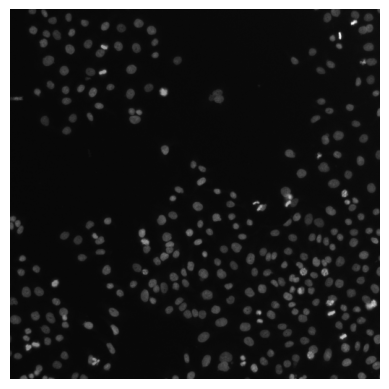

In [ ]:
img = data.human_mitosis()

plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()

In [ ]:
def implot(img, img_file, nomefiltro, kernelsize):
  plt.figure(figsize=(10, 5))

  plt.subplot(1, 2, 1)
  plt.imshow(img, cmap='gray', vmin=0, vmax=255)
  plt.title('imagem original')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(img_file, cmap='gray', vmin=0, vmax=255)
  plt.title('filtro ' + nomefiltro + ' ' + kernelsize)
  plt.axis('off')

  plt.show()

In [ ]:
def convolucao(img, kernel):
  altura, largura = img.shape
  altura_kernel, largura_kernel = kernel.shape
  margem_y = altura_kernel // 2
  margem_x = largura_kernel // 2

  img_borda = np.pad(img.astype(float),
                     ((margem_y, margem_y), (margem_x, margem_x)),
                     mode='edge')
  img_filt = np.zeros((altura, largura), dtype=float)

  for y in range(altura):
    for x in range(largura):
      soma = 0
      for i in range(altura_kernel):
        for j in range(largura_kernel):
          soma += img_borda[y + i, x + j] * kernel[altura_kernel - 1 - i,
                                                               largura_kernel - 1 - j]
      img_filt[y, x] = soma

  return img_filt

In [ ]:
def filtro_media(img, kernelsize):
  kernel = np.ones((kernelsize, kernelsize))
  kernel = kernel / (kernelsize * kernelsize)
  return convolucao(img, kernel)

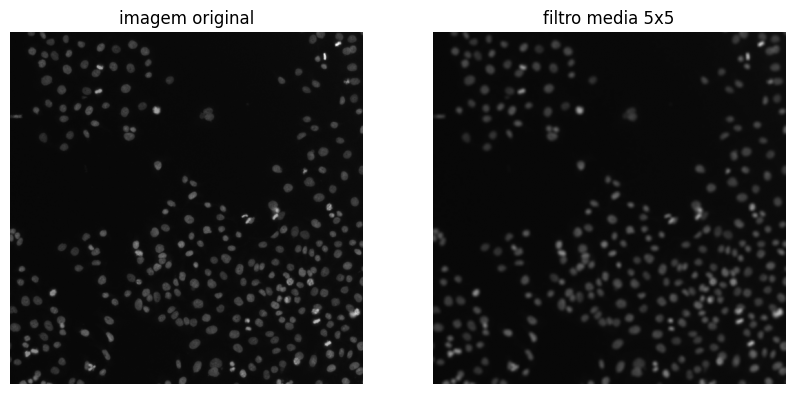

In [ ]:
img_filt = filtro_media(img, 5)
implot(img, img_filt, 'media', '5x5')

In [ ]:
def filtro_mediana(img, kernelsize):
  altura, largura = img.shape
  margem = kernelsize // 2
  img_borda = np.pad(img.astype(float), margem, mode='edge')
  img_filt = np.zeros((altura, largura), dtype=float)

  for y in range(altura):
    for x in range(largura):
      valores = []
      for i in range(kernelsize):
        for j in range(kernelsize):
          valores.append(img_borda[y + i, x + j])

      valores = sorted(valores)
      img_filt[y, x] = valores[len(valores) // 2]

  return img_filt

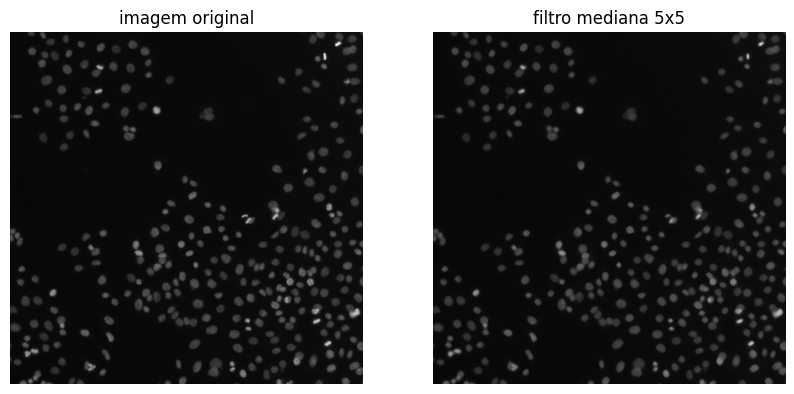

In [ ]:
img_filt = filtro_mediana(img, 5)
implot(img, img_filt, 'mediana', '5x5')

In [ ]:
def filtro_moda(img, kernelsize):
  altura, largura = img.shape
  margem = kernelsize // 2
  img_borda = np.pad(img.astype(float), margem, mode='edge')
  img_filt = np.zeros((altura, largura), dtype=float)

  for y in range(altura):
    for x in range(largura):
      frequencias = {}
      for i in range(kernelsize):
        for j in range(kernelsize):
          valor = img_borda[y + i, x + j]
          if valor in frequencias:
            frequencias[valor] += 1
          else:
            frequencias[valor] = 1

      moda = img_borda[y, x]
      maior_frequencia = 0
      for valor in frequencias:
        frequencia = frequencias[valor]
        if frequencia > maior_frequencia:
          moda = valor
          maior_frequencia = frequencia
        elif frequencia == maior_frequencia and valor < moda:
          moda = valor

      img_filt[y, x] = moda

  return img_filt

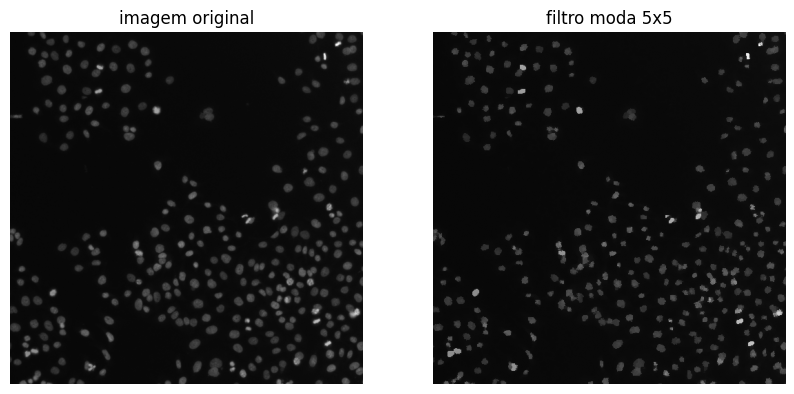

In [ ]:
img_filt = filtro_moda(img, 5)
implot(img, img_filt, 'moda', '5x5')

In [ ]:
def filtro_maxima(img, kernelsize):
  altura, largura = img.shape
  margem = kernelsize // 2
  img_borda = np.pad(img.astype(float), margem, mode='edge')
  img_filt = np.zeros((altura, largura), dtype=float)

  for y in range(altura):
    for x in range(largura):
      maior = img_borda[y, x]
      for i in range(kernelsize):
        for j in range(kernelsize):
          valor = img_borda[y + i, x + j]
          if valor > maior:
            maior = valor

      img_filt[y, x] = maior

  return img_filt

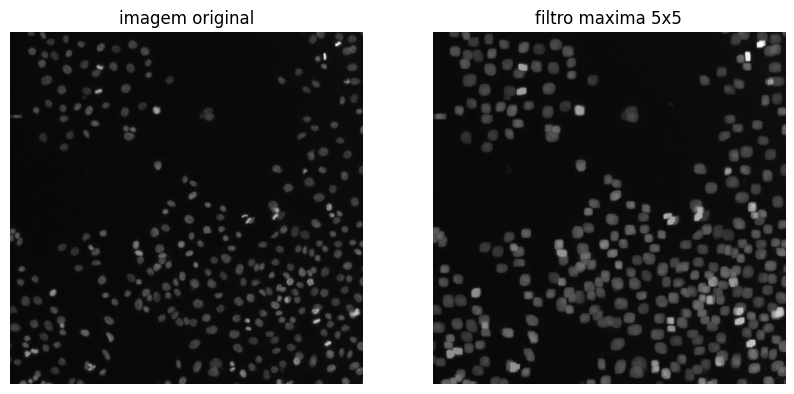

In [ ]:
img_filt = filtro_maxima(img, 5)
implot(img, img_filt, 'maxima', '5x5')